# Lab 2 — Poisson Image Editing

*Optimization Techniques for Computer Vision*

Our visual system is far more sensitive to **changes** of intensity (edges, textures) than to absolute intensity levels. **Gradient-domain editing** exploits this: instead of pasting pixel values, we paste **gradients** and let an optimization find the image whose gradients match them best. The result is the solution of a **Poisson equation**, and the edits blend seamlessly into their surroundings.

In this lab you will:

1. understand gradient-domain editing on a **1D signal**;
2. implement the discrete **gradient and divergence**, and solve the Poisson equation with a **hard constraint** (direct solver) and with a **soft constraint** (matrix-free conjugate gradient);
3. perform a **face swap** between two Leonardo portraits: align the faces by least squares (orthogonal Procrustes, via the **SVD**) and blend them seamlessly;
4. use **mixed gradients** and study **non-conservative** guidance fields;
5. apply the pipeline to **images of your choice**;
6. explore other gradient-domain edits: **texture flattening**, **local illumination change**, and **local color change**;
7. *(bonus)* implement two more edits of Pérez et al. (2003): **seamless tiling** and **monochrome transfer**.

### How to work

* **Cell legend**
    * 📘 **blue banner**: theory. Read it; the questions build on it.
    * 🟨 **yellow banner / `# 🟨 YOUR CODE HERE`**: code you must complete (replace the `raise NotImplementedError`).
    * 🟩 **green banner / `# 🟩 ANSWER CELL`**: a question, followed by the cell where you give your answer with `answer("Qx.y", ...)`. Executing it shows your answer in a **green box**.
* Many numerical answers are computed by the provided code once your implementation is correct. For multiple-choice questions, write the letter and a short justification.
* Follow the specifications in the comments, so that your numbers can be compared with the reference.

### Grading

The lab is graded on **10 points**; each question shows its points in its green banner. The optional bonus exercise is worth **1 extra point**. A table with all questions and points is at the end of the notebook.

### Hand-in

1. `Runtime → Restart session and run all`, and check that **no cell fails** (except the optional bonus, if you did not attempt it).
2. Check that every green answer box shows your answer.
3. `File → Download → Download .ipynb`, and upload that file **with all outputs**.

### Contents
0. Setup
1. Gradient-domain editing in 1D
2. The Poisson equation on images
3. Face swap
4. Mixed gradients and non-conservative fields
5. Your own swap
6. More gradient-domain edits
* Bonus: seamless tiling and monochrome transfer
* Grading table

---
## 0. Setup

In [1]:
# Only the standard scientific stack (all preinstalled on Colab)
import base64, io, functools, time

import numpy as np
import scipy.sparse as sp                 # sparse matrices
import scipy.sparse.linalg as spla        # sparse solvers, LinearOperator, CG
import scipy.ndimage as ndi               # image warping, smoothing, morphology
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont
from IPython.display import HTML, display

plt.rcParams["figure.dpi"] = 90
np.set_printoptions(precision=4, suppress=True)

**Random seeds.** Random data in this notebook is generated with NumPy's pseudo-random number generator. The **seed** sets the generator's initial state: the same seed always gives the same "random" numbers, so the notebook is **reproducible** and your results can be compared with the reference.

In [2]:
SEED_SIGNAL = 1     # Part 1: 1D test signals
SEED_LIGHT = 2      # Part 2: illumination change of the source image

In [3]:
# ---------------------------------------------------------------
# Answer display: shows an answer in a green box (orange if still missing)
# ---------------------------------------------------------------
def answer(qid, value):
    if value is None or (isinstance(value, str) and value.strip() in ("", "?")):
        style = "background:#fef7e0;border-left:6px solid #f9ab00;color:#7a4f01"
        text = "⚠️ not answered yet"
    else:
        style = "background:#e6f4ea;border-left:6px solid #34a853;color:#1e4620"
        text = f"{value:.5g}" if isinstance(value, (float, np.floating)) else str(value)
    display(HTML(f'<div style="{style};padding:6px 10px;font-family:monospace;font-size:14px">'
                 f'🟩 <b>{qid}</b>: {text}</div>'))

# ---------------------------------------------------------------
# Display and metric helpers
# ---------------------------------------------------------------
def show(images, titles=None, size=3.3, vmin=0, vmax=1):
    # Show grayscale or RGB images (values in [0, 1]) side by side
    images = list(images)
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size))
    for k, (ax, im) in enumerate(zip(np.atleast_1d(axes), images)):
        ax.imshow(np.clip(im, 0, 1), cmap="gray" if im.ndim == 2 else None, vmin=vmin, vmax=vmax)
        ax.set_axis_off()
        if titles is not None:
            ax.set_title(titles[k], fontsize=9)
    plt.tight_layout()
    plt.show()

def rmse(u, ref, region=None):
    d = (u - ref) if region is None else (u - ref)[region]
    return float(np.sqrt(np.mean(d ** 2)))

def ellipse_mask(shape, center, axes, angle_deg=0.0):
    # Boolean mask of a filled ellipse; center = (x, y), axes = (half-width, half-height) in pixels
    H, W = shape[:2]
    yy, xx = np.mgrid[0:H, 0:W]
    t = np.deg2rad(angle_deg)
    dx, dy = xx - center[0], yy - center[1]
    xr, yr = dx * np.cos(t) + dy * np.sin(t), -dx * np.sin(t) + dy * np.cos(t)
    return (xr / axes[0]) ** 2 + (yr / axes[1]) ** 2 <= 1.0

### Test images

* **Mona Lisa** (Leonardo da Vinci, c. 1503–1519, Louvre) and **Ginevra de' Benci** (Leonardo da Vinci, c. 1474–1478, National Gallery of Art, Washington): both paintings are in the **public domain**. The two black-and-white reproductions used for the face swap are embedded below, together with a low-resolution color copy (408×600) of the public-domain C2RMF reproduction of the Mona Lisa (Wikimedia Commons), used in Parts 4 and 6. The Ginevra image is stored in the painting's true orientation (landscape on the right). All images are **embedded** in the cells below as base64-encoded JPEG data, so the notebook needs no download.
* **Astronaut** (Eileen Collins, NASA, public domain), **chelsea**, **brick** and **coffee** (CC0): bundled with scikit-image (preinstalled on Colab).


In [4]:
# Embedded image data (do not edit): Mona Lisa, public-domain reproduction, JPEG, base64-encoded
MONALISA_JPG_B64 = (
    "..."
)

In [5]:
# Embedded image data (do not edit): Mona Lisa, black-and-white reproduction, JPEG, base64-encoded
MONA_BW_JPG_B64 = (
    "..."
)

In [6]:
# Embedded image data (do not edit): Ginevra de' Benci, public domain, JPEG, base64-encoded
GINEVRA_JPG_B64 = (
    "..."
)

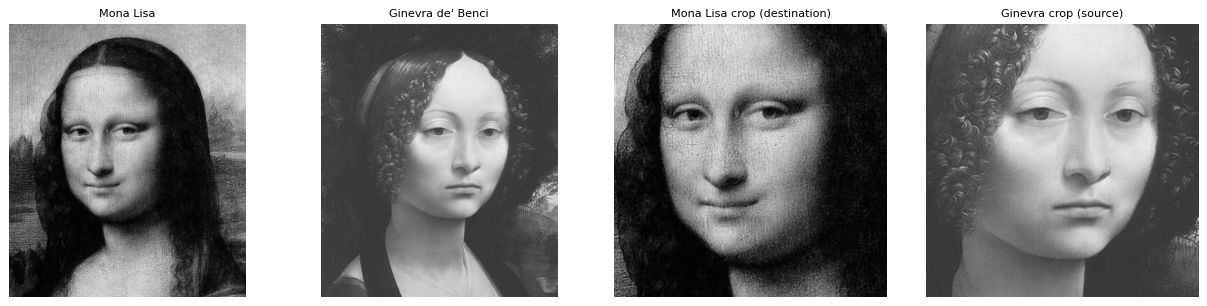

In [7]:
def load_embedded(b64):
    # Decode an embedded JPEG into RGB floats in [0, 1]
    return np.asarray(Image.open(io.BytesIO(base64.b64decode(b64))).convert("RGB")).astype(float) / 255

def face_crop(img, box, size=300):
    # Crop box = (left, top, right, bottom) in pixels, resized to size x size; RGB floats in [0, 1]
    pil = Image.fromarray((img * 255).round().astype(np.uint8)).crop(box).resize((size, size), Image.LANCZOS)
    return np.asarray(pil).astype(float) / 255

def load_skimage(name):
    from skimage import data
    im = getattr(data, name)()
    return im.astype(float) / 255

def bw_crop(img, box):
    # Crop box = (left, top, right, bottom) without resizing (black-and-white images, kept as 3 equal channels)
    l, t, r, b = box
    return img[t:b, l:r].copy()

monalisa_color = load_embedded(MONALISA_JPG_B64)                       # color painting (Parts 4, 6, bonus)
mona_full = load_embedded(MONA_BW_JPG_B64)                             # black-and-white reproductions (face swap)
ginevra_full = load_embedded(GINEVRA_JPG_B64)
mona = bw_crop(mona_full, (45, 98, 345, 398))                    # destination face (300 x 300)
ginevra = bw_crop(ginevra_full, (89, 98, 389, 398))                  # source face (300 x 300), original orientation
mona_color = face_crop(monalisa_color, (100, 40, 300, 240))            # color Mona Lisa face (300 x 300)
astro = face_crop(load_skimage("astronaut"), (120, 20, 360, 260))      # used in Part 6
show([mona_full, ginevra_full, mona, ginevra], ["Mona Lisa", "Ginevra de' Benci", "Mona Lisa crop (destination)",
     "Ginevra crop (source)"], size=3.5)

---
## 1. Gradient-domain editing in 1D

<div style="background-color:#e8f0fe; border-left:6px solid #4285f4; padding:6px 12px; font-weight:bold; color:#174ea6;">📘 1.1 Pasting values versus pasting gradients</div>

Let $f\in\mathbb{R}^N$ be a **destination** signal and $g\in\mathbb{R}^N$ a **source** signal. We want to insert the part of $g$ on an interval $\Omega=\{a,\dots,b-1\}$ into $f$.

* **Naive paste:** $u=g$ on $\Omega$ and $u=f$ elsewhere. If $g$ and $f$ have different levels, $u$ **jumps** at both ends of $\Omega$.
* **Gradient-domain paste:** keep $u=f$ outside $\Omega$, and inside $\Omega$ ask the **differences** of $u$ to match those of $g$, as well as possible:
$$
\min_u\; \tfrac12\,\|\nabla u - v\|^2 \quad\text{s.t.}\quad u_k = f_k \ \ (k\notin\Omega), \qquad v=\nabla g ,
$$
with the forward differences $(\nabla u)_k = u_{k+1}-u_k$ of Lab 1. The vector $v$ is called the **guidance field**.

**Solution.** Write $u=g+h$ inside $\Omega$. Then $\nabla u - v = \nabla h$ on the edges inside $\Omega$, so the problem becomes: minimize $\tfrac12\|\nabla h\|^2$ with $h = f-g$ fixed at the two neighbors of $\Omega$. This is **harmonic in-painting** of the boundary mismatch (Lab 1): in 1D, $h$ is the **straight line** joining the mismatches $f_{a-1}-g_{a-1}$ and $f_b-g_b$.

> Gradient-domain pasting = source + the smoothest correction that removes the jumps.

**Linear algebra.** The energy is $\tfrac12\,u^\top Q u - c^\top u + \text{const}$ with $Q=\nabla^\top\nabla$ and $c=\nabla^\top v$. With the known samples $K$ and unknowns $U$ (as in Lab 1), setting the gradient with respect to $u_U$ to zero gives

$$
\boxed{\;Q_{UU}\,u_U = c_U - Q_{UK}\,f_K\;}
$$

<div style="background-color:#fef7e0; border-left:6px solid #f9ab00; padding:6px 12px; font-weight:bold; color:#7a4f01;">🟨 TODO 1 — constrained quadratic solver with a linear term, and 1D Poisson pasting</div>


1. Extend the Lab 1 solver: minimize $\tfrac12 u^\top Qu - c^\top u$ subject to $u_K=f_K$ (if `c` is `None`, use $c=0$).
2. `paste_1d(f, g, inside)`: guidance $v=\nabla g$ on **all** edges (edges outside $\Omega$ do not matter, since $u$ is fixed there), $Q=\nabla^\top\nabla$, $c=\nabla^\top v$.

In [8]:
def grad_1d(N):
    # Forward differences: (N-1) x N sparse matrix
    return sp.diags([-np.ones(N - 1), np.ones(N - 1)], [0, 1], shape=(N - 1, N), format="csr")

def solve_constrained_quadratic(Q, f, known, c=None):
    # Minimize 1/2 u^T Q u - c^T u  subject to  u[known] = f[known]   (Q sparse, symmetric PSD)
    Q = sp.csr_matrix(Q)
    u = np.array(f, dtype=float).copy()
    c = np.zeros(len(u)) if c is None else np.asarray(c, dtype=float)
    
    # 🟨 YOUR CODE HERE    
    known = np.asarray(known)
    if known.dtype != bool:                  # also accept index arrays
        mask = np.zeros(len(u), bool); mask[known] = True; known = mask
    unk = ~known

    Q_UU = Q[unk][:, unk].tocsc()            # unknown-unknown block
    Q_UK = Q[unk][:, known]                  # unknown-known block
    rhs  = c[unk] - Q_UK @ u[known]          # c_U - Q_UK f_K
    u[unk] = spla.spsolve(Q_UU, rhs)         # sparse direct solve
    return u


def paste_1d(f, g, inside):
    # Gradient-domain pasting of g into f on the boolean interval `inside`
    # 🟨 YOUR CODE HERE
    
    N = len(f)
    D = grad_1d(N)                           # forward differences
    Q = (D.T @ D).tocsr()                    # Q = ∇ᵀ∇
    v = D @ g                                # guidance field v = ∇g (all edges)
    c = D.T @ v                              # c = ∇ᵀv
    return solve_constrained_quadratic(Q, f, ~inside, c)   # known = outside Ω

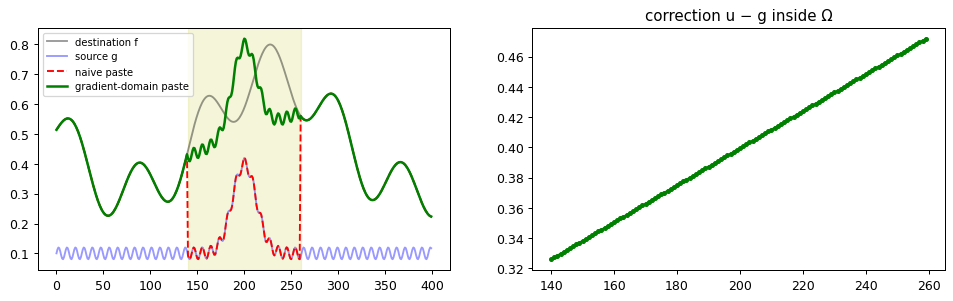

slope of the correction: 0.001225;  max deviation from a straight line: 4.11e-15


In [9]:
rng1 = np.random.default_rng(SEED_SIGNAL)
N1 = 400
t = np.arange(N1)
f1 = 0.5 + 0.2 * np.sin(2 * np.pi * t / 300 + rng1.uniform(0, 6)) + 0.1 * np.sin(2 * np.pi * t / 70)     # destination
g1 = 0.1 + 0.3 * np.exp(-((t - 200) / 18.0) ** 2) + 0.02 * np.sin(2 * np.pi * t / 9)                      # source: a bump with fine ripples
inside1 = (t >= 140) & (t < 260)

naive1 = np.where(inside1, g1, f1)
u1 = paste_1d(f1, g1, inside1)
h1 = u1 - g1                                                   # correction added to the source

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
ax[0].plot(t, f1, "k", alpha=0.4, label="destination f"); ax[0].plot(t, g1, "b", alpha=0.4, label="source g")
ax[0].plot(t, naive1, "r--", label="naive paste"); ax[0].plot(t, u1, "g", lw=2, label="gradient-domain paste")
ax[0].axvspan(140, 260, color="y", alpha=0.15); ax[0].legend(fontsize=8)
ax[1].plot(t[inside1], h1[inside1], "g.-"); ax[1].set_title("correction u − g inside Ω")
plt.show()

# Is the correction a straight line?
coef = np.polyfit(t[inside1], h1[inside1], 1)
line_dev = np.abs(h1[inside1] - np.polyval(coef, t[inside1])).max()
print(f"slope of the correction: {coef[0]:.6f};  max deviation from a straight line: {line_dev:.2e}")

<div style="background-color:#e6f4ea; border-left:6px solid #34a853; padding:6px 12px; font-weight:bold; color:#1e4620;">🟩 Question Q1.1 (0.5 points) — answer in the green cell below</div>

**Q1.1** *(0.5 points).* Report the slope of the correction $u-g$ inside $\Omega$ and its maximum deviation from a straight line. Verify the slope by hand from the mismatches $f-g$ at $k=a-1$ and $k=b$ (the correction is linear on $\{a-1,\dots,b\}$).

In [10]:
# 🟩🟩🟩 ANSWER CELL — Q1.1 🟩🟩🟩
answer("Q1.1", f"slope {coef[0]:.6f}, max deviation {line_dev:.1e}, by hand: (0.472-0.325)/(259-140) = 0.00124 aprox")

<div style="background-color:#e6f4ea; border-left:6px solid #34a853; padding:6px 12px; font-weight:bold; color:#1e4620;">🟩 Question Q1.2 (0.5 points) — answer in the green cell below</div>

**Q1.2** *(0.5 points).* What does gradient-domain pasting preserve?

* **(a)** the values of the source $g$ inside $\Omega$;
* **(b)** the variations (differences) of the source inside $\Omega$, while its level is adapted to the surroundings by adding the smoothest (harmonic) correction that removes the jumps;
* **(c)** the values of the destination $f$ inside $\Omega$;
* **(d)** the average of $f$ and $g$ inside $\Omega$.

Give the letter and a one-sentence justification.

In [11]:
# 🟩🟩🟩 ANSWER CELL — Q1.2 🟩🟩🟩
answer("Q1.2", "(b) the differences given by the gradient of g are stepped or adapted to the new space to make the transition of the border smoother while mantaining g's propperties")   # e.g. "(x) because ..."

---
## 2. The Poisson equation on images

<div style="background-color:#e8f0fe; border-left:6px solid #4285f4; padding:6px 12px; font-weight:bold; color:#174ea6;">📘 2.1 Guidance fields and the Poisson equation</div>

Let $f$ be the destination image, $\Omega$ the region to edit (the **mask**), and $\mathbf{v}=(v_i,v_j)$ a **guidance field**: the gradients we would like the result to have inside $\Omega$. Gradient-domain editing solves

$$
\min_u\; \frac12\int_\Omega \|\nabla u-\mathbf{v}\|^2\,dx \qquad\text{s.t.}\qquad u=f \ \text{ on } \partial\Omega .
$$

**Euler–Lagrange equation.** For a perturbation $\varphi$ vanishing on $\partial\Omega$,
$$
\frac{d}{dt}E(u+t\varphi)\Big|_{t=0} = \int_\Omega (\nabla u-\mathbf{v})\cdot\nabla\varphi\,dx = -\int_\Omega \big(\Delta u-\operatorname{div}\mathbf{v}\big)\,\varphi\,dx = 0
$$
(integration by parts), so the minimizer solves the **Poisson equation with Dirichlet boundary conditions**
$$
\boxed{\;\Delta u = \operatorname{div}\mathbf{v}\ \text{ in }\Omega,\qquad u=f\ \text{ on }\partial\Omega .\;}
$$

**Seamless cloning** (Pérez, Gangnet & Blake, 2003) uses the gradients of a source image $g$: $\mathbf{v}=\nabla g$. Then $\Delta(u-g)=0$ in $\Omega$: exactly as in 1D, $u = g + h$, where $h$ is the **harmonic in-painting** of the boundary mismatch $f-g$ (Lab 1). The source keeps its details; the membrane $h$ adapts its colors to the surroundings.

<div style="background-color:#e8f0fe; border-left:6px solid #4285f4; padding:6px 12px; font-weight:bold; color:#174ea6;">📘 2.2 Discrete gradient and divergence</div>

Index pixels by $(i,j)$: $i$ is the **row** (vertical direction) and $j$ the **column** (horizontal direction). The forward gradient with a Neumann boundary (as in Lab 1) is

$$
(\nabla_i u)_{i,j} = \begin{cases} u_{i+1,j}-u_{i,j} & i<H-1\\ 0 & i=H-1\end{cases}
\qquad
(\nabla_j u)_{i,j} = \begin{cases} u_{i,j+1}-u_{i,j} & j<W-1\\ 0 & j=W-1\end{cases}
$$

The discrete **divergence** is *defined* as minus the adjoint (transpose) of the gradient, $\operatorname{div}=-\nabla^\top$, so that the discrete version of integration by parts holds exactly:

$$
\langle \nabla u,\mathbf{v}\rangle = \sum_{i,j}\big[(\nabla_i u)_{i,j}(v_i)_{i,j}+(\nabla_j u)_{i,j}(v_j)_{i,j}\big] = -\langle u,\operatorname{div}\mathbf{v}\rangle \quad\text{for all } u,\mathbf{v}.
$$

This gives **backward differences** with special first and last rows/columns. For the $i$ component:

$$
(\partial_i^- v_i)_{i,j} = \begin{cases} (v_i)_{0,j} & i=0\\ (v_i)_{i,j}-(v_i)_{i-1,j} & 0<i<H-1\\ -(v_i)_{H-2,j} & i=H-1\end{cases}
\qquad \operatorname{div}\mathbf{v} = \partial_i^- v_i + \partial_j^- v_j ,
$$

and similarly for $j$. Then $\Delta = \operatorname{div}\circ\nabla$ is the 5-point Laplacian with Neumann boundary of Lab 1. Implementing $\nabla$ and $\operatorname{div}$ directly on 2D arrays (**matrix-free**) is fast and memory-efficient; the adjoint identity is the standard test that an implementation is correct.

<div style="background-color:#fef7e0; border-left:6px solid #f9ab00; padding:6px 12px; font-weight:bold; color:#7a4f01;">🟨 TODO 2.A — gradient, divergence and composite guidance field</div>


Implement the three functions with NumPy array operations (slicing; no loops, no matrices).

In [12]:
def im_fwd_gradient(u):
    # Forward differences with Neumann boundary. Returns (grad_i, grad_j), same shape as u.
    # 🟨 YOUR CODE HERE
    gi = np.zeros_like(u); gj = np.zeros_like(u)
    gi[:-1, :] = u[1:, :] - u[:-1, :]      # vertical difference, last row stays 0
    gj[:, :-1] = u[:, 1:] - u[:, :-1]      # horizontal difference, last column stays 0
    return gi, gj

def im_bwd_divergence(vi, vj):
    # Backward-difference divergence, the negative adjoint of im_fwd_gradient
    # 🟨 YOUR CODE HERE
    di = np.zeros_like(vi); dj = np.zeros_like(vj)
    di[0, :]    =  vi[0, :]                    
    di[1:-1, :] =  vi[1:-1, :] - vi[:-2, :]    
    di[-1, :]   = -vi[-2, :]                   
    dj[:, 0]    =  vj[:, 0]
    dj[:, 1:-1] =  vj[:, 1:-1] - vj[:, :-2]
    dj[:, -1]   = -vj[:, -2]
    return di + dj

def composite_gradients(u1, u2, mask):
    # Guidance field: gradient of u1 where mask is True, gradient of u2 elsewhere. Returns (vi, vj).
    # 🟨 YOUR CODE HERE
    g1i, g1j = im_fwd_gradient(u1)
    g2i, g2j = im_fwd_gradient(u2)
    return np.where(mask, g1i, g2i), np.where(mask, g1j, g2j)

In [13]:
# Adjoint test with random arrays: <grad u, v> + <u, div v> must vanish
rng_test = np.random.default_rng(0)
u_t = rng_test.standard_normal((37, 53))
vi_t, vj_t = rng_test.standard_normal((2, 37, 53))
gi_t, gj_t = im_fwd_gradient(u_t)
lhs = np.sum(gi_t * vi_t + gj_t * vj_t)
rhs = -np.sum(u_t * im_bwd_divergence(vi_t, vj_t))
adjoint_err = abs(lhs - rhs) / abs(lhs)
print(f"<grad u, v> = {lhs:.10f},  -<u, div v> = {rhs:.10f},  relative difference = {adjoint_err:.2e}")

# The 5-point stencil: div(grad(delta image))
e = np.zeros((5, 5)); e[2, 2] = 1
print("div(grad(e)) =\n", im_bwd_divergence(*im_fwd_gradient(e)))

<grad u, v> = -11.2098651518,  -<u, div v> = -11.2098651518,  relative difference = 7.92e-16
div(grad(e)) =
 [[ 0.  0.  0.  0.  0.]
 [ 0.  0.  1.  0.  0.]
 [ 0.  1. -4.  1.  0.]
 [ 0.  0.  1.  0.  0.]
 [ 0.  0.  0.  0. -0.]]


<div style="background-color:#e6f4ea; border-left:6px solid #34a853; padding:6px 12px; font-weight:bold; color:#1e4620;">🟩 Question Q2.1 (0.5 points) — answer in the green cell below</div>

**Q2.1** *(0.5 points).* Relative difference of the adjoint test. What does a value of order $10^{-15}$ tell you, and what would a value of order $10^{-2}$ indicate?

In [14]:
# 🟩🟩🟩 ANSWER CELL — Q2.1 🟩🟩🟩
answer("Q2.1", f"{adjoint_err:.1e}: An error of 10^-16 like in this case indicates that div is indeed the negative adjoint of the gradient, an error of 10^-2 would indicate a problem/bug in the solver and therefore would not minimize the intended energy function.")

<div style="background-color:#e8f0fe; border-left:6px solid #4285f4; padding:6px 12px; font-weight:bold; color:#174ea6;">📘 2.3 Two ways to impose the boundary condition</div>

**(a) Hard constraint (direct solver).** As in Lab 1, the pixels outside $\Omega$ are known ($u=f$) and only the pixels in $\Omega$ are unknown. With the sparse gradient matrix $G=\begin{pmatrix}G_i\\G_j\end{pmatrix}$, the energy is $\tfrac12\|Gu-\mathbf{v}\|^2 = \tfrac12 u^\top Q u - c^\top u+\text{const}$ with

$$
Q = G^\top G = -\Delta,\qquad c = G^\top \mathbf{v} = -\operatorname{div}\mathbf{v},
$$

and `solve_constrained_quadratic(Q, f, known, c)` from Part 1 solves it.

**(b) Soft constraint (the "β" formulation).** Instead of fixing $u=f$ outside $\Omega$, penalize the deviation with a weight $\beta_p\ge 0$ per pixel, $\beta = \beta_0\,(1-\text{mask})$, and use the guidance $\nabla f$ outside $\Omega$:

$$
\min_u\;\tfrac12\|\nabla u-\mathbf{v}\|^2+\tfrac12\sum_p\beta_p\,(u_p-f_p)^2
\quad\Longrightarrow\quad
\underbrace{\big(-\Delta+\operatorname{diag}(\beta)\big)}_{A}\,u=-\operatorname{div}\mathbf{v}+\beta\odot f .
$$

$A$ is symmetric positive definite (as soon as some $\beta_p>0$), so **conjugate gradients** apply. CG only needs the product $u\mapsto Au = -\operatorname{div}(\nabla u)+\beta\odot u$, which we compute **matrix-free** with the functions above (`scipy.sparse.linalg.LinearOperator`). As $\beta_0\to\infty$, the soft solution tends to the hard one; for small $\beta_0$ the result drifts away from $f$. Note also that CG's usual stopping rule, $\|b-Au_k\|\le \text{tol}\cdot\|b\|$, is *relative* to the right-hand side $b$.

<div style="background-color:#fef7e0; border-left:6px solid #f9ab00; padding:6px 12px; font-weight:bold; color:#7a4f01;">🟨 TODO 2.B — hard and soft Poisson solvers</div>

In [15]:
@functools.lru_cache(maxsize=None)
def sparse_grad(H, W):
    # Sparse matrices G_i, G_j with G_i @ u.ravel() == im_fwd_gradient(u)[0].ravel(), etc.
    def d(n):
        main = -np.ones(n); main[-1] = 0.0
        return sp.diags([main, np.ones(n - 1)], [0, 1], shape=(n, n), format="csr")
    Gi = sp.kron(d(H), sp.identity(W)).tocsr()
    Gj = sp.kron(sp.identity(H), d(W)).tocsr()
    return Gi, Gj

def poisson_hard(f, vi, vj, mask):
    # Hard constraint: u = f outside the mask; solve -Delta u = -div v inside (one channel)
    H, W = f.shape
    Gi, Gj = sparse_grad(H, W)
    # 🟨 YOUR CODE HERE
    H, W = f.shape
    Gi, Gj = sparse_grad(H, W)
    Q = (Gi.T @ Gi + Gj.T @ Gj).tocsr()                # Q = GᵀG = -Δ
    c = Gi.T @ vi.ravel() + Gj.T @ vj.ravel()          # c = Gᵀv = -div v
    known = (~mask.astype(bool)).ravel()               
    u = solve_constrained_quadratic(Q, f.ravel(), known, c)
    return u.reshape(H, W)

def poisson_linear_operator(u, beta):
    # Matrix-free action of A = -Delta + diag(beta) on a 2D array u
    # 🟨 YOUR CODE HERE
    gi, gj = im_fwd_gradient(u)
    return -im_bwd_divergence(gi, gj) + beta * u  
    

def cg_solve(A, b, x0, tol=1e-6, maxiter=5000):
    # Conjugate gradients (scipy); returns the solution and the number of iterations
    count = [0]
    def cb(xk):
        count[0] += 1
    try:
        x, info = spla.cg(A, b, x0=x0, rtol=tol, maxiter=maxiter, callback=cb)
    except TypeError:                                   # older SciPy versions use `tol`
        x, info = spla.cg(A, b, x0=x0, tol=tol, maxiter=maxiter, callback=cb)
    return x, count[0]

def poisson_soft(f, vi, vj, beta, tol=1e-6, maxiter=5000):
    # Soft constraint: solve (-Delta + diag(beta)) u = -div v + beta*f with matrix-free CG, starting from f.
    # Returns (u, number of CG iterations).
    H, W = f.shape
    # 🟨 YOUR CODE HERE
    H, W = f.shape
    A = spla.LinearOperator((H*W, H*W),
            matvec=lambda x: poisson_linear_operator(x.reshape(H, W), beta).ravel(),
            dtype=float)
    b = (-im_bwd_divergence(vi, vj) + beta * f).ravel()   # -div v + β⊙f
    x, its = cg_solve(A, b, f.ravel(), tol=tol, maxiter=maxiter)
    return x.reshape(H, W), its

### Experiment 2.a — cloning under a change of illumination

We take a destination image $f$ and build a **source** $g$ that shows the *same scene* under different illumination. Pasting the region $\Omega$ from $g$ into $f$ should ideally give back $f$. Two cases:

* **offset:** $g = f + \text{offset}$;
* **gain and gradient:** $g = \text{gain}\cdot f + \text{offset} + \text{ramp}$, where the ramp is a linear brightness gradient across the image.

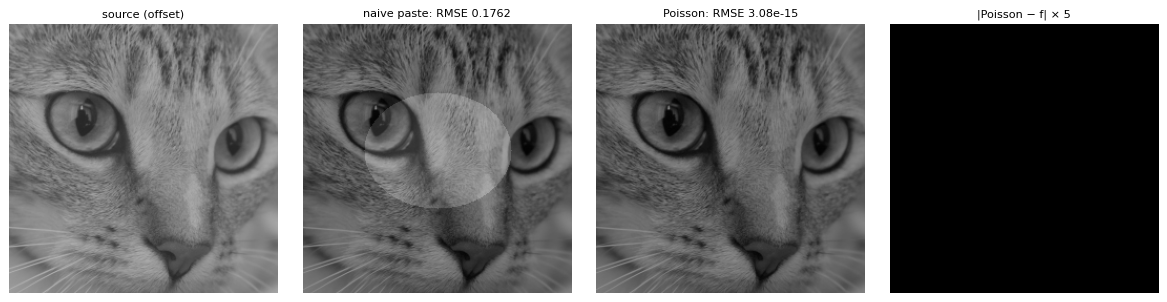

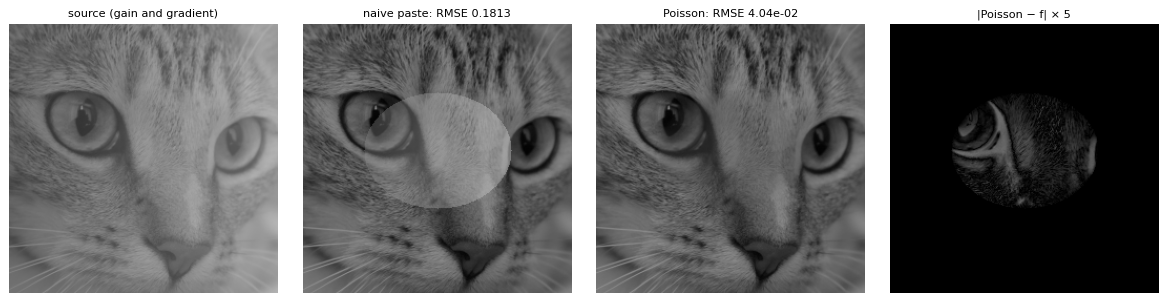

In [16]:
rng2 = np.random.default_rng(SEED_LIGHT)
cat = load_skimage("chelsea") @ np.array([0.299, 0.587, 0.114])
cat = cat[22:278, 100:356]                                      # 256 x 256 grayscale destination
H2, W2 = cat.shape
omega = ellipse_mask(cat.shape, (128, 120), (70, 55))
offset, gain = rng2.uniform(0.15, 0.25), rng2.uniform(0.6, 0.8)
ramp = 0.3 * np.arange(W2)[None, :] / W2 * np.ones((H2, 1))
sources = {"offset": cat + offset, "gain and gradient": gain * cat + offset + ramp}

poisson_res, naive_res = {}, {}
for name, g in sources.items():
    vi, vj = composite_gradients(g, cat, omega)
    poisson_res[name] = poisson_hard(cat, vi, vj, omega)
    naive_res[name] = np.where(omega, g, cat)
    show([g, naive_res[name], poisson_res[name], 5 * np.abs(poisson_res[name] - cat)],
         [f"source ({name})", f"naive paste: RMSE {rmse(naive_res[name], cat, omega):.4f}",
          f"Poisson: RMSE {rmse(poisson_res[name], cat, omega):.2e}", "|Poisson − f| × 5"], vmax=1.3)

<div style="background-color:#e6f4ea; border-left:6px solid #34a853; padding:6px 12px; font-weight:bold; color:#1e4620;">🟩 Question Q2.2 (0.5 points) — answer in the green cell below</div>

**Q2.2** *(0.5 points).* RMSE inside $\Omega$ (with respect to the destination $f$) of the naive paste and of Poisson cloning, for both cases. *(Computed automatically.)*

In [17]:
# 🟩🟩🟩 ANSWER CELL — Q2.2 🟩🟩🟩
answer("Q2.2", "; ".join(f"{k}: naive {rmse(naive_res[k], cat, omega):.4f}, Poisson {rmse(poisson_res[k], cat, omega):.2e}"
                         for k in sources))

<div style="background-color:#e6f4ea; border-left:6px solid #34a853; padding:6px 12px; font-weight:bold; color:#1e4620;">🟩 Question Q2.3 (0.5 points) — answer in the green cell below</div>

**Q2.3** *(0.5 points).* Why does Poisson cloning recover $f$ exactly (up to round-off) in the *offset* case, but not in the *gain and gradient* case? Which components of an illumination change can gradient-domain cloning remove, and which can it not? *(Two or three sentences.)*

In [18]:
# 🟩🟩🟩 ANSWER CELL — Q2.3 🟩🟩🟩
answer("Q2.3", "Because the Poisson paste solves a PDE that enforces smooth transitions and preserves the gradient information from the source image, it results in a more seamless blend compared to the naive paste which simply replaces pixel values without considering the surrounding context.")

### Experiment 2.b — soft constraint and matrix-free CG

Same problem (*gain and gradient* source), now with the β formulation for several values of $\beta_0$, solved with CG (starting from $f$) at two relative tolerances, $10^{-6}$ and $10^{-10}$. We compare with the hard-constraint solution.

tol 1e-06, beta0 =    0.01:   284 CG iterations, max |u_soft - u_hard| = 3.91e-02
tol 1e-06, beta0 =     0.1:   264 CG iterations, max |u_soft - u_hard| = 3.11e-02
tol 1e-06, beta0 =     1.0:   233 CG iterations, max |u_soft - u_hard| = 1.88e-02
tol 1e-06, beta0 =    10.0:   244 CG iterations, max |u_soft - u_hard| = 4.57e-03
tol 1e-06, beta0 =   100.0:   156 CG iterations, max |u_soft - u_hard| = 8.38e-03
tol 1e-06, beta0 =  1000.0:    42 CG iterations, max |u_soft - u_hard| = 5.83e-02
tol 1e-10, beta0 =    0.01:   485 CG iterations, max |u_soft - u_hard| = 3.91e-02
tol 1e-10, beta0 =     0.1:   431 CG iterations, max |u_soft - u_hard| = 3.11e-02
tol 1e-10, beta0 =     1.0:   423 CG iterations, max |u_soft - u_hard| = 1.88e-02
tol 1e-10, beta0 =    10.0:   534 CG iterations, max |u_soft - u_hard| = 4.57e-03
tol 1e-10, beta0 =   100.0:   598 CG iterations, max |u_soft - u_hard| = 5.58e-04
tol 1e-10, beta0 =  1000.0:   540 CG iterations, max |u_soft - u_hard| = 5.72e-05


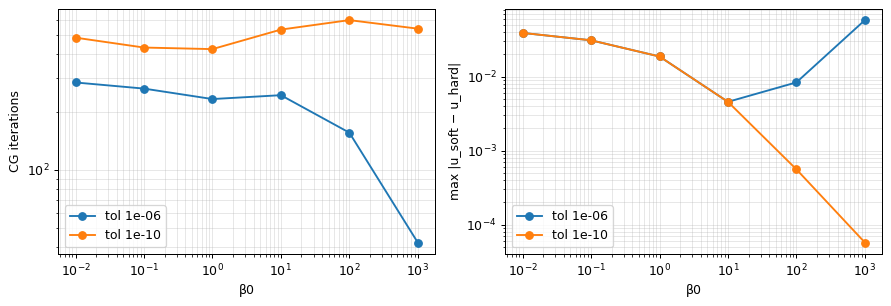

In [19]:
g_b = sources["gain and gradient"]
vi_b, vj_b = composite_gradients(g_b, cat, omega)
u_hard = poisson_res["gain and gradient"]
beta0s = [1e-2, 1e-1, 1.0, 10.0, 100.0, 1000.0]
soft_table = {}
for tol in [1e-6, 1e-10]:
    for b0 in beta0s:
        u_soft, its = poisson_soft(cat, vi_b, vj_b, b0 * (~omega), tol=tol, maxiter=20000)
        soft_table[(tol, b0)] = (its, np.abs(u_soft - u_hard).max())
        print(f"tol {tol:.0e}, beta0 = {b0:>7}: {its:5d} CG iterations, max |u_soft - u_hard| = {soft_table[(tol, b0)][1]:.2e}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for tol in [1e-6, 1e-10]:
    ax[0].loglog(beta0s, [soft_table[(tol, b)][0] for b in beta0s], "o-", label=f"tol {tol:.0e}")
    ax[1].loglog(beta0s, [soft_table[(tol, b)][1] for b in beta0s], "o-", label=f"tol {tol:.0e}")
ax[0].set_ylabel("CG iterations"); ax[1].set_ylabel("max |u_soft − u_hard|")
for a in ax:
    a.set_xlabel("β0"); a.grid(True, which="both", alpha=0.3); a.legend()
plt.tight_layout(); plt.show()

<div style="background-color:#e6f4ea; border-left:6px solid #34a853; padding:6px 12px; font-weight:bold; color:#1e4620;">🟩 Question Q2.4 (1 point) — answer in the green cell below</div>

**Q2.4** *(1 point).* Report the iteration counts and the distances to the hard-constraint solution (they are listed by the answer cell). Then choose the statement that best explains them, with a short justification:

* **(a)** with a tight tolerance, the soft solution approaches the hard one as $\beta_0$ grows (roughly like $1/\beta_0$); with the loose tolerance and a large $\beta_0$, CG stops too early, because the right-hand side is dominated by the large term $\beta\odot f$ outside $\Omega$, so the *relative* residual becomes small while $u$ inside $\Omega$ has not converged yet;
* **(b)** the result does not depend on $\beta_0$, because the guidance field is the same;
* **(c)** a small $\beta_0$ gives the solution closest to the hard constraint;
* **(d)** CG diverges for large $\beta_0$, because $A$ is no longer symmetric.

In [20]:
# 🟩🟩🟩 ANSWER CELL — Q2.4 🟩🟩🟩
answer("Q2.4", " | ".join(f"tol {t:.0e}, b0={b:g}: {v[0]} it, {v[1]:.1e}" for (t, b), v in soft_table.items()) + "(a) With tol 1e-10 the error drops roughly like 1/beta0, so the soft solution approaches the hard one.")

---
## 3. Face swap

<div style="background-color:#e8f0fe; border-left:6px solid #4285f4; padding:6px 12px; font-weight:bold; color:#174ea6;">📘 3.1 Aligning two faces: least squares with the SVD</div>

Before blending, the source face must be **aligned** with the destination face. We mark $n$ corresponding **landmarks** in both images; here $n=4$ **support points**: the outer corners of the two eyebrows and the outer corners of the lips: $p_k$ in the source and $q_k$ in the destination, as $(x,y)$ coordinates. We look for the **similarity transform** (scale $s>0$, rotation $R$, translation $t$) that best maps one set onto the other in the least-squares sense:

$$
\min_{s,\,R,\,t}\; \sum_{k=1}^{n}\big\|\,s R\,p_k + t - q_k\big\|^2 ,\qquad R^\top R = I,\ \det R = 1 .
$$

**Solution (orthogonal Procrustes; Umeyama, 1991).** Let $\bar p,\bar q$ be the centroids, $\tilde p_k = p_k-\bar p$, $\tilde q_k = q_k-\bar q$, and

$$
\Sigma = \frac1n\sum_k \tilde q_k\,\tilde p_k^\top \in\mathbb{R}^{2\times 2} = U D V^\top \quad\text{(SVD)}.
$$

Then
$$
R = U\,\mathrm{diag}\big(1,\ \det(UV^\top)\big)\,V^\top,\qquad
s = \frac{\operatorname{tr}\!\big(D\,\mathrm{diag}(1,\det(UV^\top))\big)}{\frac1n\sum_k\|\tilde p_k\|^2},\qquad
t = \bar q - sR\,\bar p .
$$

*Why the SVD?* For fixed $s$ and centered points, minimizing over $R$ amounts to maximizing $\operatorname{tr}(R^\top\Sigma)$, and over rotations this is achieved by "replacing the singular values of $\Sigma$ by ones". The correction $\det(UV^\top)$ excludes reflections. The translation aligns the centroids, and $s$ follows from a 1D least-squares problem.

**Warping.** To resample the source in the destination frame we use the **inverse map**: each destination pixel $x$ takes the source value at $s^{-1}R^\top(x-t)$, interpolated bilinearly (provided function `warp_similarity`).

**Mirroring the source.** Leonardo turned the two sitters in opposite directions: Mona Lisa's body is turned towards the viewer's left, Ginevra's towards the viewer's right. Pasting Ginevra's face as it is would combine two mirrored poses (and the asymmetries of a three-quarter view differ on the two sides of a face). A similarity transform cannot undo this: mirroring is a reflection ($\det = -1$), which the correction $\det(UV^\top)$ explicitly excludes. We can, however, **flip the source left–right first**, $g(x,y)\mapsto g(W-1-x,\,y)$, and mirror its points accordingly ($x\mapsto W-1-x$; the "left" and "right" labels swap). Whether this helps is checked with **check points** (pupils and nose tip) that are *not* used in the fit: after alignment, they should land close to the corresponding points of the destination.

**The mask.** The region $\Omega$ to be replaced is the **quadrilateral** with the four support points as vertices (eyebrow corners on top, lip corners at the bottom), enlarged by a **margin** of $m$ pixels (all pixels within distance $m$ of the quadrilateral; a morphological dilation with a disk). Since the lip corners lie *on* the quadrilateral, the margin is what brings the whole mouth (upper and lower lip) and the eyebrows inside $\Omega$, and it keeps the boundary $\partial\Omega$ on smooth skin, where $f$ and the warped source differ the least.

<div style="background-color:#fef7e0; border-left:6px solid #f9ab00; padding:6px 12px; font-weight:bold; color:#7a4f01;">🟨 TODO 3 — least-squares similarity transform</div>


Implement `fit_similarity(P, Q)` following the formulas above (use `np.linalg.svd`).

In [21]:
def fit_similarity(P, Q):
    # Least-squares similarity transform mapping points P (n x 2) onto Q (n x 2): Q ≈ s * P @ R.T + t
    # Returns s (float), R (2 x 2 rotation), t (2,)
    P, Q = np.asarray(P, float), np.asarray(Q, float)
    # 🟨 YOUR CODE HERE
    n = len(P)
    p_bar, q_bar = P.mean(axis=0), Q.mean(axis=0)               # centroids
    Pc, Qc = P - p_bar, Q - q_bar                               # centered points
    Sigma = Qc.T @ Pc / n                                       # (1/n) sum_k q~_k p~_k^T  (2 x 2)
    U, D, Vt = np.linalg.svd(Sigma)
    S = np.diag([1.0, np.linalg.det(U @ Vt)])                   # det correction: excludes reflections
    R = U @ S @ Vt
    s = np.trace(np.diag(D) @ S) / (np.sum(Pc ** 2) / n)        # tr(D S) / ((1/n) sum ||p~_k||^2)
    t = q_bar - s * R @ p_bar
    return s, R, t

def apply_similarity(P, s, R, t):
    return s * np.asarray(P, float) @ R.T + t

def warp_similarity(src, s, R, t, shape):
    # Resample src (H x W x C) in the destination frame: dst(x) = src(R^T (x - t) / s), bilinear interpolation
    H, W = shape[:2]
    yy, xx = np.mgrid[0:H, 0:W]
    X = np.stack([xx.ravel(), yy.ravel()], axis=1).astype(float)          # destination (x, y)
    Psrc = (X - t) @ R / s                                                 # inverse map: R^T (x - t) / s
    coords = [Psrc[:, 1].reshape(H, W), Psrc[:, 0].reshape(H, W)]          # (row, col) for map_coordinates
    return np.stack([ndi.map_coordinates(src[..., c], coords, order=1, mode="nearest")
                     for c in range(src.shape[2])], axis=-1)

# Check on a synthetic example: rotate by 20 degrees, scale by 1.5, translate
th = np.deg2rad(20); R_true = np.array([[np.cos(th), -np.sin(th)], [np.sin(th), np.cos(th)]])
P_test = np.random.default_rng(0).uniform(0, 100, (6, 2))
s_e, R_e, t_e = fit_similarity(P_test, apply_similarity(P_test, 1.5, R_true, np.array([10.0, -5.0])))
print(f"recovered scale {s_e:.6f}, angle {np.rad2deg(np.arctan2(R_e[1, 0], R_e[0, 0])):.6f} deg, t = {t_e}")

recovered scale 1.500000, angle 20.000000 deg, t = [10. -5.]


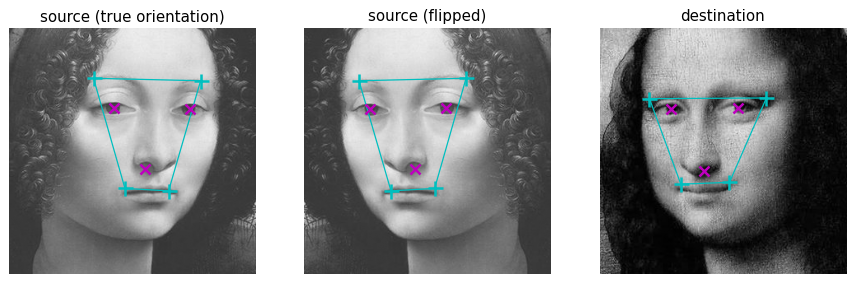

 without flipping: scale 0.886, rotation   0.02 deg, support-point residual 13.23 px, check-point error 11.56 px
   after flipping: scale 0.887, rotation   1.58 deg, support-point residual 12.95 px, check-point error 10.10 px


In [22]:
# Support points (x, y) in the 300 x 300 crops, listed clockwise as seen in the image:
#   outer corner of the left eyebrow, outer corner of the right eyebrow, right lip corner, left lip corner
# They define the alignment AND the vertices of the quadrilateral mask.
LM_MONA = np.array([[60.0, 85.8], [202.5, 85.0], [157.5, 187.8], [98.2, 190.0]], float)
LM_GINEVRA_ORIG = np.array([[102.5, 61.0], [233.0, 64.0], [194.0, 198.2], [140.8, 195.2]], float)      # Ginevra crop, painting's true orientation
# Check points, NOT used in the fit (to evaluate the alignment): left pupil, right pupil, nose tip
CHK_MONA = np.array([[85.9, 98.0], [168.3, 96.8], [126.0, 173.5]], float)
CHK_GINEVRA_ORIG = np.array([[127.0, 97.2], [219.9, 98.9], [164.8, 171.2]], float)

def flip_lr(img, pts, order=(1, 0, 3, 2)):
    # Mirror an image left-right and its points: x -> W-1-x. Left and right swap, so the points are
    # re-ordered to keep their meaning ("left" = image left): order (1, 0, 3, 2) for the 4 support points,
    # (1, 0, 2) for the check points.
    W = img.shape[1]
    q = np.asarray(pts, float).copy()
    q[:, 0] = W - 1 - q[:, 0]
    return img[:, ::-1].copy(), q[list(order)]

ginevra_flip, LM_GINEVRA = flip_lr(ginevra, LM_GINEVRA_ORIG)
_, CHK_GINEVRA = flip_lr(ginevra, CHK_GINEVRA_ORIG, order=(1, 0, 2))

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for a, im, lm, ck, name in zip(ax, [ginevra, ginevra_flip, mona], [LM_GINEVRA_ORIG, LM_GINEVRA, LM_MONA],
                               [CHK_GINEVRA_ORIG, CHK_GINEVRA, CHK_MONA],
                               ["source (true orientation)", "source (flipped)", "destination"]):
    a.imshow(im); a.plot(*np.vstack([lm, lm[:1]]).T, "c-", lw=1); a.plot(lm[:, 0], lm[:, 1], "c+", ms=12, mew=2)
    a.plot(ck[:, 0], ck[:, 1], "mx", ms=8, mew=2); a.set_title(name); a.set_axis_off()
plt.show()

def similarity_report(P, Q, P_chk, Q_chk):
    # Fit on the support points; return scale, angle (deg), RMS residual on the support points
    # and RMS error of the transferred check points (pixels)
    s_, R_, t_ = fit_similarity(P, Q)
    res = np.sqrt(np.mean(np.sum((apply_similarity(P, s_, R_, t_) - Q) ** 2, axis=1)))
    chk = np.sqrt(np.mean(np.sum((apply_similarity(P_chk, s_, R_, t_) - Q_chk) ** 2, axis=1)))
    return s_, np.rad2deg(np.arctan2(R_[1, 0], R_[0, 0])), res, chk

fits = {"without flipping": similarity_report(LM_GINEVRA_ORIG, LM_MONA, CHK_GINEVRA_ORIG, CHK_MONA),
         "after flipping": similarity_report(LM_GINEVRA, LM_MONA, CHK_GINEVRA, CHK_MONA)}
for name, (s_, ang, res, chk) in fits.items():
    print(f"{name:>17}: scale {s_:.3f}, rotation {ang:6.2f} deg, support-point residual {res:.2f} px, "
          f"check-point error {chk:.2f} px")


<div style="background-color:#e6f4ea; border-left:6px solid #34a853; padding:6px 12px; font-weight:bold; color:#1e4620;">🟩 Question Q3.1 (0.9 points) — answer in the green cell below</div>

**Q3.1** *(0.9 points).* Report the scale, the rotation angle, the residual on the four support points and the error on the three **check points** (pupils and nose tip, not used in the fit), without and after flipping the source. *(Computed automatically.)* Then explain in two sentences (i) why the check points, rather than the residual of the fit, are the right criterion to decide whether to flip, and (ii) why `fit_similarity` cannot find the mirror transform by itself.

In [23]:
# 🟩🟩🟩 ANSWER CELL — Q3.1 🟩🟩🟩
answer("Q3.1", "; ".join(f"{k}: s={v[0]:.3f}, angle={v[1]:.2f} deg, fit residual={v[2]:.2f} px, check error={v[3]:.2f} px"
                         for k, v in fits.items()) + ".  (i) The fit residual only tells how well the 4 points used in the fit match, so it is not a fair test. The check points are not used in the fit, so their error shows if the alignment is really good for the rest of the face. (ii) fit_similarity only gives rotations (det R = +1) because of the det(UV^T) correction, and a mirror is a reflection (det = -1), so it can't find it. We have to flip the image and the points first.")

<div style="background-color:#e8f0fe; border-left:6px solid #4285f4; padding:6px 12px; font-weight:bold; color:#174ea6;">📘 3.2 Blending: naive, feathered and Poisson</div>

With the (flipped) source warped into the destination frame, we compare three ways to combine them inside the mask $\Omega$:

* **naive paste:** $u = g$ in $\Omega$, $u=f$ outside;
* **feathering (alpha blending):** $u = \alpha\,g+(1-\alpha)\,f$, where $\alpha$ is a blurred version of the mask: the transition is softened, but colors still mix linearly;
* **Poisson cloning:** solve $\Delta u=\Delta g$ in $\Omega$, $u=f$ on $\partial\Omega$, **independently for each color channel**.

To quantify the visibility of the seam, we use the mean absolute difference between neighboring pixels across the mask boundary (over all channels):

$$
J(u) = \operatorname{mean}_{(p,q):\ p\in\Omega,\ q\notin\Omega,\ p\sim q}\ |u_p - u_q| .
$$

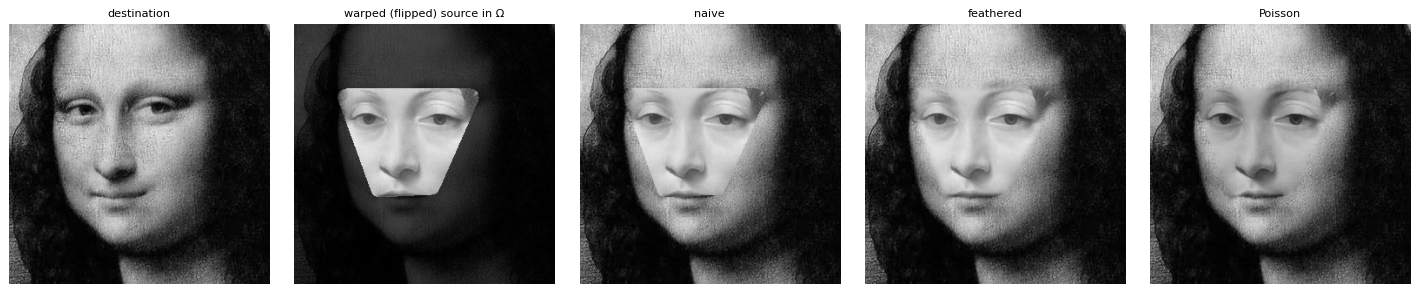

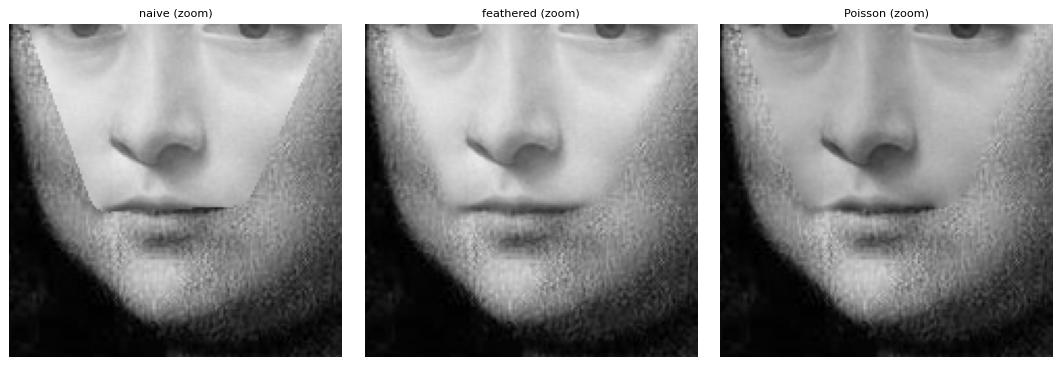

{'naive': 0.1552, 'feathered': 0.0334, 'Poisson': 0.0419, 'destination (reference)': 0.0472}


In [24]:
def quad_mask(points, shape, margin=10):
    # Filled quadrilateral through the 4 support points (x, y), in drawing order, enlarged by a margin:
    # all pixels within `margin` pixels of the quadrilateral (morphological dilation with a disk)
    canvas = Image.new("L", (shape[1], shape[0]), 0)
    ImageDraw.Draw(canvas).polygon([tuple(p) for p in np.asarray(points, float)], fill=255)
    quad = np.asarray(canvas) > 127
    yy, xx = np.mgrid[-margin:margin + 1, -margin:margin + 1]
    return ndi.binary_dilation(quad, structure=xx ** 2 + yy ** 2 <= margin ** 2)

def seam_jump(u, mask):
    # Mean |u_p - u_q| over pairs of neighbors with exactly one pixel in the mask (all channels)
    u = u if u.ndim == 3 else u[..., None]
    di = mask[1:, :] != mask[:-1, :]
    dj = mask[:, 1:] != mask[:, :-1]
    jumps = np.concatenate([np.abs(u[1:, :] - u[:-1, :])[di].ravel(), np.abs(u[:, 1:] - u[:, :-1])[dj].ravel()])
    return float(jumps.mean())

def poisson_clone_color(src, dst, mask):
    # Poisson cloning (hard constraint), channel by channel
    out = np.empty_like(dst)
    for c in range(dst.shape[2]):
        vi, vj = composite_gradients(src[..., c], dst[..., c], mask)
        out[..., c] = poisson_hard(dst[..., c], vi, vj, mask)
    return np.clip(out, 0, 1)

def face_swap(src, dst, lm_src, lm_dst, margin=10, feather_sigma=3.0):
    # Align the source with one least-squares similarity (4 support points), build the quadrilateral mask
    # in the destination frame, and blend in three ways
    s_, R_, t_ = fit_similarity(lm_src, lm_dst)
    warped = warp_similarity(src, s_, R_, t_, dst.shape)     # whole source in the destination frame
    mask = quad_mask(lm_dst, dst.shape, margin)
    alpha = ndi.gaussian_filter(mask.astype(float), feather_sigma)[..., None]
    return {"mask": mask, "warped source": warped,
            "naive": np.where(mask[..., None], warped, dst),
            "feathered": alpha * warped + (1 - alpha) * dst,
            "Poisson": poisson_clone_color(warped, dst, mask)}

swap = face_swap(ginevra_flip, mona, LM_GINEVRA, LM_MONA, margin=10)
mask3 = swap["mask"]
show([mona, np.where(mask3[..., None], swap["warped source"], 0.3 * mona), swap["naive"], swap["feathered"], swap["Poisson"]],
     ["destination", "warped (flipped) source in Ω", "naive", "feathered", "Poisson"], size=3.2)
zoom = (slice(110, 270), slice(50, 210))
show([swap[k][zoom] for k in ["naive", "feathered", "Poisson"]], ["naive (zoom)", "feathered (zoom)", "Poisson (zoom)"], size=4)
jumps = {k: seam_jump(swap[k], mask3) for k in ["naive", "feathered", "Poisson"]}
jumps["destination (reference)"] = seam_jump(mona, mask3)
print({k: round(v, 4) for k, v in jumps.items()})

<div style="background-color:#e6f4ea; border-left:6px solid #34a853; padding:6px 12px; font-weight:bold; color:#1e4620;">🟩 Question Q3.2 (0.6 points) — answer in the green cell below</div>

**Q3.2** *(0.6 points).* Report the seam measure $J$ of the three methods and of the destination itself (the natural variation across the same boundary). *(Computed automatically.)* Which method brings the seam closest to the natural variation of the destination?

In [25]:
# 🟩🟩🟩 ANSWER CELL — Q3.2 🟩🟩🟩
answer("Q3.2", ", ".join(f"{k}: {v:.4f}" for k, v in jumps.items()) + ".  The Poisson cloning is the closest to the natural variation of the destination (0.0419 vs 0.0472). The naive paste has a really big jump (0.1552) because it just replaces the pixel values and the border is clearly visible. The feathered one is even lower than the destination (0.0334), because it only blurs the transition and mixes the gray levels linearly, so the border gets too smooth. Poisson makes the values of the border match f and keeps the gradients of the source, so the seam looks like a natural change of the image.")

In [26]:
mean_gray = {k: swap[k][mask3].mean() for k in ["warped source", "Poisson"]}
mean_gray["destination"] = mona[mask3].mean()
for k, v in mean_gray.items():
    print(f"mean gray level inside the mask, {k:>13}: {v:.3f}")

mean gray level inside the mask, warped source: 0.709
mean gray level inside the mask,       Poisson: 0.593
mean gray level inside the mask,   destination: 0.563


<div style="background-color:#e6f4ea; border-left:6px solid #34a853; padding:6px 12px; font-weight:bold; color:#1e4620;">🟩 Question Q3.3 (0.5 points) — answer in the green cell below</div>

**Q3.3** *(0.5 points).* Compare the mean gray level inside the mask of the warped source, of the Poisson result and of the destination. Towards which one does the Poisson result move? *(Numbers computed automatically; add one sentence.)*

In [27]:
# 🟩🟩🟩 ANSWER CELL — Q3.3 🟩🟩🟩
answer("Q3.3", "; ".join(f"{k}: {v:.3f}" for k, v in mean_gray.items()) + ".  The Poisson result moves towards the destination (0.593 vs 0.563, while the warped source is 0.709), because the border has to match f so the brightness of the new face is adapted to the skin around it and only the gradients of the source are kept.")

<div style="background-color:#e6f4ea; border-left:6px solid #34a853; padding:6px 12px; font-weight:bold; color:#1e4620;">🟩 Question Q3.4 (0.5 points) — answer in the green cell below</div>

**Q3.4** *(0.5 points).* Which statement explains the adaptation of the brightness?

* **(a)** Poisson cloning normalizes the source to zero mean;
* **(b)** per channel, $u = g + h$ with $h$ harmonic and $h = f - g$ on $\partial\Omega$: the membrane $h$ carries the brightness difference between the two images from the boundary into the region, shifting the source levels smoothly towards the destination's;
* **(c)** the feathering kernel mixes the gray levels;
* **(d)** the shift is due to the bilinear interpolation of the warp.

Give the letter and a one-sentence justification.

In [28]:
# 🟩🟩🟩 ANSWER CELL — Q3.4 🟩🟩🟩
answer("Q3.4", "(b) because the only thing that fixes the brightness in Poisson cloning is the condition u = f on the border (the equation only uses the gradients of g, so it can't know g's brightness), which is why the result goes to the destination's levels, and it is not (a) since nothing is normalized to zero mean, nor (c) since the Poisson result doesn't use any feathering, nor (d) since the interpolation only resamples the source and doesn't change its mean level by that much.")

---
## 4. Mixed gradients and non-conservative guidance fields

<div style="background-color:#e8f0fe; border-left:6px solid #4285f4; padding:6px 12px; font-weight:bold; color:#174ea6;">📘 4.1 Mixing gradients</div>

Seamless cloning *replaces* the destination's texture inside $\Omega$ by the source's. Sometimes we want both: paint a mural on a brick wall, add writing to a textured surface, insert an object with holes. **Mixed gradients** (Pérez et al., 2003) keep, at every pixel, whichever gradient is **stronger**:

$$
\mathbf{v}_p = \begin{cases}\nabla g_p & \text{if } \|\nabla g_p\| > \|\nabla f_p\|\\ \nabla f_p & \text{otherwise}\end{cases}\qquad (p\in\Omega),
$$

where $\|\nabla g_p\| = \sqrt{(\nabla_i g)_p^2+(\nabla_j g)_p^2}$. Outside $\Omega$, $\mathbf{v}=\nabla f$ as before.

<div style="background-color:#e8f0fe; border-left:6px solid #4285f4; padding:6px 12px; font-weight:bold; color:#174ea6;">📘 4.2 Conservative and non-conservative fields</div>

A vector field $\mathbf{v}$ is **conservative** (integrable) if it is the gradient of some image: $\mathbf{v}=\nabla u$. In 2D, a conservative field has zero **curl**: the "mixed second derivatives" agree, $\partial_i v_j = \partial_j v_i$. With forward differences, on the pixels $i<H-1$, $j<W-1$:

$$
(\operatorname{curl}\mathbf{v})_{i,j} = \big[(v_j)_{i+1,j}-(v_j)_{i,j}\big] - \big[(v_i)_{i,j+1}-(v_i)_{i,j}\big] .
$$

For $\mathbf{v}=\nabla u$, both brackets equal $u_{i+1,j+1}-u_{i+1,j}-u_{i,j+1}+u_{i,j}$, so the curl vanishes exactly. Composite fields (gradients of $g$ in one place, of $f$ in another) and mixed fields are in general **not** conservative: no image has exactly these gradients.

**What does the Poisson solver do then?** It returns the least-squares answer: among the images with the prescribed boundary values, the one whose gradient is **closest** to $\mathbf{v}$, i.e. a projection of $\mathbf{v}$ onto the gradient fields. The residual $\nabla u-\mathbf{v}$ has two origins:

* **non-integrability:** the "rotational" part of $\mathbf{v}$ (in the sense of the **Helmholtz decomposition**), which no image can reproduce; it is signalled by a non-zero curl;
* **incompatibility with the boundary values:** even for $\mathbf{v}=\nabla g$, the boundary condition $u=f$ forces the correction $u=g+h$, and $\nabla u-\mathbf{v}=\nabla h$ is the gradient of the harmonic membrane $h$ (Section 2.1).

**A failure mode: bleeding.** If the mask boundary crosses regions of very different colors in the destination, the harmonic correction carries those colors into the whole region (for example, a dark background "bleeding" into a pasted face). Placing the boundary in a uniform area of the destination avoids it.

<div style="background-color:#fef7e0; border-left:6px solid #f9ab00; padding:6px 12px; font-weight:bold; color:#7a4f01;">🟨 TODO 4 — mixed gradients and discrete curl</div>

In [29]:
def mixed_gradients(g, f, mask):
    # Per pixel in the mask: the stronger of grad g and grad f (Euclidean norm of the 2-vector); grad f outside
    # 🟨 YOUR CODE HERE

    gi_g, gj_g = im_fwd_gradient(g)
    gi_f, gj_f = im_fwd_gradient(f)

    # Select the entire gradient vector with the larger Euclidean norm
    source_is_stronger = (
        gi_g ** 2 + gj_g ** 2 >
        gi_f ** 2 + gj_f ** 2
    )

    # Source gradients are allowed only inside the mask
    use_source = mask & source_is_stronger

    vi = np.where(use_source, gi_g, gi_f)
    vj = np.where(use_source, gj_g, gj_f)

    return vi, vj

def discrete_curl(vi, vj):
    # Forward-difference curl on the (H-1) x (W-1) pixels: (vj[i+1,j]-vj[i,j]) - (vi[i,j+1]-vi[i,j])
    # 🟨 YOUR CODE HERE

    d_i_vj = vj[1:, :-1] - vj[:-1, :-1]
    d_j_vi = vi[:-1, 1:] - vi[:-1, :-1]

    return d_i_vj - d_j_vi # Output shape: (H - 1, W - 1)

# Check: the curl of a gradient field vanishes
print("max |curl(grad u)| =", np.abs(discrete_curl(*im_fwd_gradient(np.random.default_rng(0).random((20, 30))))).max())

max |curl(grad u)| = 0.0


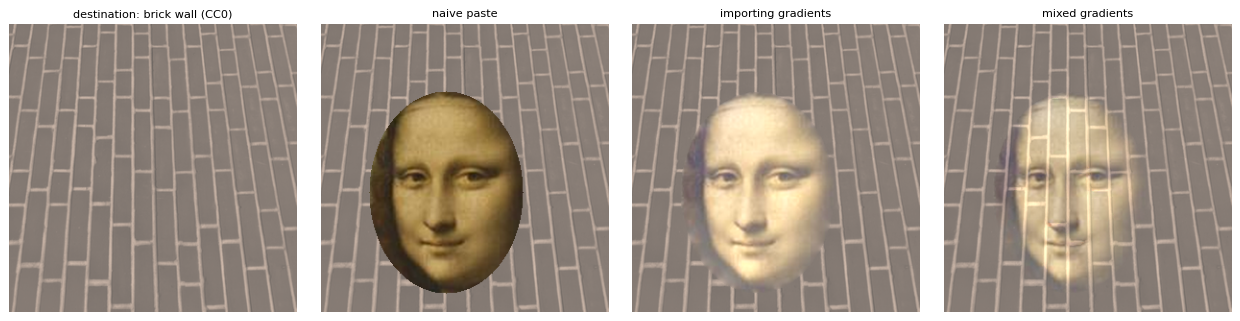

 importing gradients: relative curl 0.137, relative residual ||grad u - v|| / ||v|| = 0.194
     mixed gradients: relative curl 0.204, relative residual ||grad u - v|| / ||v|| = 0.144


In [30]:
brick = Image.fromarray((load_skimage("brick") * 255).astype(np.uint8)).resize((300, 300), Image.LANCZOS)
wall = np.repeat(np.asarray(brick).astype(float)[..., None] / 255, 3, axis=2)
wall = 0.25 + 0.7 * wall * np.array([1.0, 0.85, 0.75])                # a warm, mid-gray brick wall
omega4 = ellipse_mask(wall.shape, (130, 175), (80, 105))

def clone_with(field_fn, src, dst, mask):
    # Poisson editing channel by channel with a given guidance-field function; also returns the fields
    out, fields = np.empty_like(dst), []
    for c in range(3):
        vi, vj = field_fn(src[..., c], dst[..., c], mask)
        out[..., c] = poisson_hard(dst[..., c], vi, vj, mask)
        fields.append((vi, vj))
    return np.clip(out, 0, 1), fields

res4 = {"importing gradients": clone_with(composite_gradients, mona_color, wall, omega4),
        "mixed gradients": clone_with(mixed_gradients, mona_color, wall, omega4)}
show([wall, np.where(omega4[..., None], mona_color, wall)] + [r[0] for r in res4.values()],
     ["destination: brick wall (CC0)", "naive paste"] + list(res4.keys()), size=3.5)

def field_stats(u, fields, mask):
    # Relative curl and relative residual of the guidance fields inside the mask (summed over channels)
    m = mask[:-1, :-1]
    curl2 = sum(np.sum(discrete_curl(vi, vj)[m] ** 2) for vi, vj in fields)
    v2 = sum(np.sum(vi[mask] ** 2 + vj[mask] ** 2) for vi, vj in fields)
    r2 = 0.0
    for c, (vi, vj) in enumerate(fields):
        gi, gj = im_fwd_gradient(u[..., c])
        r2 += np.sum((gi - vi)[mask] ** 2 + (gj - vj)[mask] ** 2)
    return np.sqrt(curl2 / v2), np.sqrt(r2 / v2)

stats4 = {}
for k, (u, fields) in res4.items():
    u_unclipped = np.stack([poisson_hard(wall[..., c], *fields[c], omega4) for c in range(3)], axis=-1)
    stats4[k] = field_stats(u_unclipped, fields, omega4)
    print(f"{k:>20}: relative curl {stats4[k][0]:.3f}, relative residual ||grad u - v|| / ||v|| = {stats4[k][1]:.3f}")

<div style="background-color:#e6f4ea; border-left:6px solid #34a853; padding:6px 12px; font-weight:bold; color:#1e4620;">🟩 Question Q4.1 (0.5 points) — answer in the green cell below</div>

**Q4.1** *(0.5 points).* Report the relative curl $\|\operatorname{curl}\mathbf{v}\|_\Omega/\|\mathbf{v}\|_\Omega$ of the two guidance fields. *(Computed automatically.)* Where is the curl of the *importing* field concentrated, and why is it not zero although $\nabla g$ is a gradient?

In [31]:
# 🟩🟩🟩 ANSWER CELL — Q4.1 🟩🟩🟩
answer("Q4.1", ", ".join(f"{k}: {v[0]:.3f}" for k, v in stats4.items()) + 
       ". The 0.0 sanity check applies to a single gradient field. The importing field combines grad(g) inside the mask with grad(f) outside, so its curl is concentrated near the mask boundary where the two fields switch.")

<div style="background-color:#e6f4ea; border-left:6px solid #34a853; padding:6px 12px; font-weight:bold; color:#1e4620;">🟩 Question Q4.2 (0.5 points) — answer in the green cell below</div>

**Q4.2** *(0.5 points).* Report the relative residual $\|\nabla u-\mathbf{v}\|_\Omega/\|\mathbf{v}\|_\Omega$ of the two solutions. *(Computed automatically.)* The mixed field has the **larger** curl but the **smaller** residual. Using the two origins of the residual (Section 4.2), explain why.

In [32]:
# 🟩🟩🟩 ANSWER CELL — Q4.2 🟩🟩🟩
answer("Q4.2", ", ".join(f"{k}: {v[1]:.3f}" for k, v in stats4.items()) +
        ". this is because the residual comes from both non-integrability and boundary incompatibility. Although the mixed field has larger curl, it retains more destination gradients and is therefore more compatible with the fixed destination boundary values, reducing the harmonic correction enough to give a smaller overall residual.")

<div style="background-color:#e6f4ea; border-left:6px solid #34a853; padding:6px 12px; font-weight:bold; color:#1e4620;">🟩 Question Q4.3 (0.5 points) — answer in the green cell below</div>

**Q4.3** *(0.5 points).* Compare the two results visually. Which statement is correct?

* **(a)** both results are identical;
* **(b)** importing gradients replaces the bricks by the smooth painting (the joints disappear inside the mask), while mixed gradients keep the strong brick joints and the strong features of the painting, so the face looks painted *on* the wall;
* **(c)** mixed gradients keep only the painting;
* **(d)** mixed gradients produce a visible seam at the mask boundary.

Give the letter and a one-sentence justification.

In [33]:
# 🟩🟩🟩 ANSWER CELL — Q4.3 🟩🟩🟩
answer("Q4.3", "(b) The mixed result keeps the wall’s strong brick edges while also preserving the important facial features, creating a painted-on-wall appearance.")   # e.g. "(x) because ..."

---
## 5. Your own swap

Apply the pipeline to two face images of your choice, for example two public-domain portraits from [Wikimedia Commons](https://commons.wikimedia.org) or museum open-access collections (e.g. the [National Gallery of Art](https://www.nga.gov/open-access-images.html), CC0), or photos of yourself and your teammates (with their consent). Use roughly frontal or three-quarter faces.

1. Load both images and crop them to $300\times300$ with `face_crop`, so that each face fills about half of the crop.
2. Read the four support points of each crop (outer corners of the left and right eyebrows, then right and left lip corners, i.e. clockwise as seen in the image) from the gridded plots produced by `show_grid`. If the two faces turn in opposite directions, mirror the source first with `flip_lr`.
3. Run `face_swap` and show the results.

In [ ]:
def upload_file():
    # On Colab: opens a file picker and returns the uploaded file name
    try:
        from google.colab import files
    except ImportError:
        print("Not running on Colab: put the file next to the notebook and use its name directly.")
        return None
    uploaded = files.upload()
    return next(iter(uploaded)) if uploaded else None

def load_image_file(path):
    return np.asarray(Image.open(path).convert("RGB")).astype(float) / 255

def show_grid(img, step=20):
    # Show an image with a coordinate grid, to read landmark positions (x = column, y = row)
    plt.figure(figsize=(6, 6)); plt.imshow(img)
    plt.xticks(range(0, img.shape[1] + 1, step), fontsize=7); plt.yticks(range(0, img.shape[0] + 1, step), fontsize=7)
    plt.grid(alpha=0.4); plt.show()

<div style="background-color:#fef7e0; border-left:6px solid #f9ab00; padding:6px 12px; font-weight:bold; color:#7a4f01;">🟨 TODO 5 — your images and landmarks</div>

In [ ]:
# name1, name2 = upload_file(), upload_file()
# my_src = face_crop(load_image_file(name1), (left, top, right, bottom))
# my_dst = face_crop(load_image_file(name2), (left, top, right, bottom))
# show_grid(my_src); show_grid(my_dst)
# lm_src = np.array([[x, y], ...], float); lm_dst = np.array([[x, y], ...], float)   # 4 points each
# my_src, lm_src = flip_lr(my_src, lm_src)   # only if the faces turn in opposite directions
raise NotImplementedError("🟨 Load your images and set the landmarks")
my_swap = face_swap(my_src, my_dst, lm_src, lm_dst)
show([my_src, my_dst, my_swap["naive"], my_swap["Poisson"]], ["source", "destination", "naive", "Poisson"])

<div style="background-color:#e6f4ea; border-left:6px solid #34a853; padding:6px 12px; font-weight:bold; color:#1e4620;">🟩 Question Q5.1 (1 point) — answer in the green cell below</div>

**Q5.1** *(1 point).* In three or four sentences: which images did you use, how well did the alignment and the blending work, and which artifacts remain (e.g. bleeding, mismatched texture or lighting direction)? Relate them to the theory.

In [ ]:
# 🟩🟩🟩 ANSWER CELL — Q5.1 🟩🟩🟩
answer("Q5.1", "?")

---
## 6. More gradient-domain edits

<div style="background-color:#e8f0fe; border-left:6px solid #4285f4; padding:6px 12px; font-weight:bold; color:#174ea6;">📘 6.1 Editing the guidance field</div>

Poisson cloning takes the guidance field from another image. Many other edits only **modify the gradients of the image itself** inside $\Omega$ and re-integrate them with the same solver (Pérez et al., 2003):

* **Texture flattening:** keep the gradients only on strong edges, set them to zero elsewhere:
$$\mathbf{v} = M\odot\nabla f,\qquad M_p = 1 \text{ if } p \text{ is an edge pixel},\ 0 \text{ otherwise}.$$
Inside $\Omega$, $u$ is then piecewise harmonic between the edges: fine texture disappears, the main structures stay ("cartoon" effect).

* **Local illumination change:** compress large gradients and amplify small ones,
$$\mathbf{v} = \alpha^{\beta}\,\|\nabla f\|^{-\beta}\,\nabla f ,$$
with $\beta\approx 0.2$ and $\alpha$ equal to $0.2$ times the mean gradient magnitude in $\Omega$. Applied to the **logarithm** of the image (so that gradients measure *relative* changes, as for the visual system), this reduces highlights and brightens shadows. It is the local version of gradient-domain high-dynamic-range compression (Fattal, Lischinski & Werman, 2002).

* **Local color change:** clone the **color** image into its own **grayscale** version (or into a recolored version) inside $\Omega$. The harmonic correction makes the color fade smoothly into the surroundings, so the mask does not need to follow the object's outline exactly.

<div style="background-color:#fef7e0; border-left:6px solid #f9ab00; padding:6px 12px; font-weight:bold; color:#7a4f01;">🟨 TODO 6 — guidance fields for flattening and illumination change</div>

In [ ]:
def flattening_guidance(f, edges):
    # v = edges * grad f (one channel; edges is a boolean image)
    # 🟨 YOUR CODE HERE
    raise NotImplementedError("🟨 Complete this part")

def illumination_guidance(L, mask, beta=0.2, alpha_factor=0.2):
    # v = alpha^beta * |grad L|^(-beta) * grad L  (one channel L, e.g. a log image); v = 0 where grad L = 0.
    # alpha = alpha_factor * mean of |grad L| over the mask.
    # 🟨 YOUR CODE HERE
    raise NotImplementedError("🟨 Complete this part")

In [ ]:
# 6.a Texture flattening on Mona Lisa's face (removes part of the craquelure)
omega6a = ellipse_mask(mona_color.shape, (128, 180), (62, 80))
lum = mona_color @ np.array([0.299, 0.587, 0.114])
smag = np.hypot(*im_fwd_gradient(ndi.gaussian_filter(lum, 1.0)))
edges = smag > np.percentile(smag[omega6a], 85)                       # strongest 15% of the gradients in Omega
flat = np.stack([poisson_hard(mona_color[..., c], *flattening_guidance(mona_color[..., c], edges), omega6a) for c in range(3)], -1)
flat = np.clip(flat, 0, 1)
show([mona_color, edges & omega6a, flat], ["original", "edge pixels used (in Ω)", "flattened"], size=4)
grad_ratio = (np.hypot(*im_fwd_gradient(flat @ np.array([0.299, 0.587, 0.114])))[omega6a].mean()
              / np.hypot(*im_fwd_gradient(lum))[omega6a].mean())
print(f"mean gradient magnitude in Omega, after / before: {grad_ratio:.3f}")

<div style="background-color:#e6f4ea; border-left:6px solid #34a853; padding:6px 12px; font-weight:bold; color:#1e4620;">🟩 Question Q6.1 (0.5 points) — answer in the green cell below</div>

**Q6.1** *(0.5 points).* Report the ratio of the mean gradient magnitude in $\Omega$ after and before flattening. *(Computed automatically.)* Which structures of the face survive, and why?

In [ ]:
# 🟩🟩🟩 ANSWER CELL — Q6.1 🟩🟩🟩
answer("Q6.1", f"{grad_ratio:.3f}.  ?")

In [ ]:
# 6.b Local illumination change on the coffee image (CC0): reduce the highlights on the cup handle and saucer
coffee = load_skimage("coffee")
omega6b = ellipse_mask(coffee.shape, (225, 262), (45, 48)) | ellipse_mask(coffee.shape, (150, 205), (45, 30))
logc = np.log(coffee + 1e-2)
relit = np.stack([poisson_hard(logc[..., c], *illumination_guidance(logc[..., c], omega6b), omega6b) for c in range(3)], -1)
relit = np.clip(np.exp(relit) - 1e-2, 0, 1)
lum_before = (coffee @ np.array([0.299, 0.587, 0.114]))[omega6b]
lum_after = (relit @ np.array([0.299, 0.587, 0.114]))[omega6b]
show([coffee, np.where(omega6b[..., None], coffee, 0.3 * coffee), relit], ["original", "Ω", "local illumination change"], size=4.5)
print(f"luminance in Omega: max {lum_before.max():.3f} -> {lum_after.max():.3f};  "
      f"99th percentile {np.percentile(lum_before, 99):.3f} -> {np.percentile(lum_after, 99):.3f}")

<div style="background-color:#e6f4ea; border-left:6px solid #34a853; padding:6px 12px; font-weight:bold; color:#1e4620;">🟩 Question Q6.2 (0.5 points) — answer in the green cell below</div>

**Q6.2** *(0.5 points).* Report the maximum and the 99th percentile of the luminance in $\Omega$ before and after the edit. *(Computed automatically.)* Why do we work with the logarithm of the image, and what happens to the dark parts of $\Omega$?

In [ ]:
# 🟩🟩🟩 ANSWER CELL — Q6.2 🟩🟩🟩
answer("Q6.2", f"max {lum_before.max():.3f} -> {lum_after.max():.3f}, p99 {np.percentile(lum_before, 99):.3f} -> "
               f"{np.percentile(lum_after, 99):.3f}.  ?")

In [ ]:
# 6.c Local color change: keep the face in color, the rest in grayscale (no TODO here)
gray3 = np.repeat((astro @ np.array([0.299, 0.587, 0.114]))[..., None], 3, axis=2)
omega6c = ellipse_mask(astro.shape, (131, 125), (62, 80))
color_pop = poisson_clone_color(astro, gray3, omega6c)
show([astro, np.where(omega6c[..., None], astro, gray3), color_pop],
     ["original", "naive: color inside Ω", "Poisson: color cloned into grayscale"], size=4)

<div style="background-color:#e6f4ea; border-left:6px solid #34a853; padding:6px 12px; font-weight:bold; color:#1e4620;">🟩 Question Q6.3 (0.5 points) — answer in the green cell below</div>

**Q6.3** *(0.5 points).* Compare the naive result and the Poisson result near the boundary of $\Omega$. Which statement is correct?

* **(a)** the Poisson result is gray everywhere, since the destination is gray;
* **(b)** the Poisson result keeps the face's colors in the center of $\Omega$ but fades them towards gray near the boundary, because the harmonic correction equals (gray − color) on $\partial\Omega$; no sharp color edge appears even though the ellipse does not follow the face outline;
* **(c)** the Poisson result shows a sharp color edge along the ellipse, like the naive one;
* **(d)** the Poisson result inverts the colors.

Give the letter and a one-sentence justification.

In [ ]:
# 🟩🟩🟩 ANSWER CELL — Q6.3 🟩🟩🟩
answer("Q6.3", "?")   # e.g. "(x) because ..."

---
## Bonus exercise (optional): more edits from Pérez et al. (2003)

<div style="background-color:#fef7e0; border-left:6px solid #f9ab00; padding:6px 12px; font-weight:bold; color:#7a4f01;">⭐ BONUS EXERCISE — optional, 1 extra point</div>

Two more gradient-domain edits from the original paper (P. Pérez, M. Gangnet, A. Blake, "Poisson image editing", *ACM SIGGRAPH* 2003, [doi:10.1145/882262.882269](https://doi.org/10.1145/882262.882269)), both with the solvers you already have.

<div style="background-color:#e8f0fe; border-left:6px solid #4285f4; padding:6px 12px; font-weight:bold; color:#174ea6;">📘 A.1 Seamless tiling</div>

A texture patch $f$ (size $H\times W$) is **tiled** by repeating it. If its opposite borders do not match, the tiling shows a grid of seams. Pérez et al. solve the Poisson equation **on the whole patch** with the guidance $\mathbf{v}=\nabla f$, and **periodic-compatible boundary values**: the top and bottom rows are both set to their average, and so are the left and right columns,

$$
u_{0,j} = u_{H-1,j} = \tfrac12\big(f_{0,j}+f_{H-1,j}\big),\qquad
u_{i,0} = u_{i,W-1} = \tfrac12\big(f_{i,0}+f_{i,W-1}\big),
$$

(the four corners take the average of the four corner values). The interior keeps the texture's gradients, and the low-frequency illumination differences between opposite borders are absorbed by the harmonic correction. Since the first and last rows (columns) of $u$ are now identical, the tile to repeat is `u[:-1, :-1]`.

<div style="background-color:#e8f0fe; border-left:6px solid #4285f4; padding:6px 12px; font-weight:bold; color:#174ea6;">📘 A.2 Monochrome transfer</div>

Poisson cloning of a color source imports the gradients of **all three color channels**. When only the **texture** of the source is wanted, but the colors of the destination should be kept, Pérez et al. clone the gradients of a **grayscale** version of the source into each channel of the destination: $\mathbf{v}_c = \nabla\,\mathrm{gray}(g)$ for $c\in\{R,G,B\}$. The color variations of the source are discarded; only luminance details are transferred.

Here the source is black and white anyway: we clone the (flipped) **black-and-white Ginevra** into the **color** Mona Lisa. Per channel, $u_c = \mathrm{gray}(g) + h_c$ with $h_c$ harmonic and $h_c = f_c-\mathrm{gray}(g)$ on $\partial\Omega$: all the color inside $\Omega$ comes from the boundary.

<div style="background-color:#fef7e0; border-left:6px solid #f9ab00; padding:6px 12px; font-weight:bold; color:#7a4f01;">🟨 TODO A — seamless tiling and monochrome transfer</div>

In [ ]:
def seamless_tile(f):
    # Seamless tiling (one channel): u = f's gradients inside, averaged opposite borders as Dirichlet values.
    # Use poisson_hard with the mask of interior pixels (all pixels except the outer frame).
    # 🟨 YOUR CODE HERE
    raise NotImplementedError("🟨 Complete this part")

def monochrome_clone(src, dst, mask):
    # Clone the gradients of the grayscale source into every channel of dst (hard constraint)
    # 🟨 YOUR CODE HERE
    raise NotImplementedError("🟨 Complete this part")

In [ ]:
# A.1 Tiling a wood patch from the coffee image (CC0); its illumination varies across the patch
patch = coffee[10:140, 450:590]
tile_naive = np.tile(patch[:-1, :-1], (3, 3, 1))
patch_seamless = np.stack([seamless_tile(patch[..., c]) for c in range(3)], axis=-1)
tile_poisson = np.tile(patch_seamless[:-1, :-1], (3, 3, 1))
show([patch, tile_naive, tile_poisson], ["patch", "naive tiling (3 x 3)", "seamless tiling (3 x 3)"], size=4)

def tile_seam(T, h, w):
    # Mean |jump| across the tile borders (all channels), vs. the mean |difference| between other neighbors
    di = np.abs(T[1:] - T[:-1]); dj = np.abs(T[:, 1:] - T[:, :-1])
    rows = np.arange(1, T.shape[0]) % h == 0; cols = np.arange(1, T.shape[1]) % w == 0
    seam = np.concatenate([di[rows].ravel(), dj[:, cols].ravel()]).mean()
    rest = np.concatenate([di[~rows].ravel(), dj[:, ~cols].ravel()]).mean()
    return seam, rest

h_t, w_t = patch.shape[0] - 1, patch.shape[1] - 1
seams = {"naive": tile_seam(tile_naive, h_t, w_t), "seamless": tile_seam(tile_poisson, h_t, w_t)}
for k, (sj, rj) in seams.items():
    print(f"{k:>9}: mean jump across tile borders {sj:.4f}, elsewhere {rj:.4f}")

# A.2 Monochrome transfer: the black-and-white Ginevra into the color Mona Lisa
LM_MONA_COLOR = np.array([[90, 155], [168, 154], [151, 227], [101, 229]], float)      # support points in the color crop
swap_c = face_swap(ginevra_flip, mona_color, LM_GINEVRA, LM_MONA_COLOR, margin=10)
mono = monochrome_clone(swap_c["warped source"], mona_color, swap_c["mask"])
zoom_c = (slice(100, 280), slice(40, 220))
show([mona_color[zoom_c], swap_c["naive"][zoom_c], mono[zoom_c]],
     ["destination (zoom)", "naive paste (zoom)", "monochrome transfer (zoom)"], size=4)

def chroma_dist(u, ref, mask):
    # Mean distance between the chromaticities (r, g, b) / (r + g + b) of u and ref inside the mask
    cu = u / (u.sum(axis=2, keepdims=True) + 1e-6); cr = ref / (ref.sum(axis=2, keepdims=True) + 1e-6)
    return float(np.linalg.norm(cu - cr, axis=2)[mask].mean())

chroma = {"naive paste": chroma_dist(swap_c["naive"], mona_color, swap_c["mask"]),
          "monochrome transfer": chroma_dist(mono, mona_color, swap_c["mask"])}
print("mean chromaticity distance to the color Mona Lisa inside the mask:", {k: round(v, 4) for k, v in chroma.items()})

<div style="background-color:#e6f4ea; border-left:6px solid #34a853; padding:6px 12px; font-weight:bold; color:#1e4620;">🟩 Question QA (1 bonus point) — answer in the green cell below</div>

**QA** *(1 bonus point).* Report the mean jump across the tile borders for naive and seamless tiling, and the mean chromaticity distance to the color Mona Lisa inside the mask for the naive paste and for monochrome transfer. *(Computed automatically.)* In two sentences: what does seamless tiling change in the patch, and where do the colors of the monochrome-transfer result come from?

In [ ]:
# 🟩🟩🟩 ANSWER CELL — QA 🟩🟩🟩
answer("QA", "?")

---
## Grading table

| question | topic | points | score |
|---|---|---|---|
| Q1.1 | 1D: correction is a straight line | 0.5 | |
| Q1.2 | 1D: what is preserved | 0.5 | |
| Q2.1 | adjoint test gradient/divergence | 0.5 | |
| Q2.2 | RMSE naive vs Poisson (illumination) | 0.5 | |
| Q2.3 | which illumination changes are removed | 0.5 | |
| Q2.4 | soft constraint: beta0, CG tolerance, accuracy | 1 | |
| Q3.1 | Procrustes alignment (SVD) and mirroring | 0.9 | |
| Q3.2 | seam measure naive/feathered/Poisson | 0.6 | |
| Q3.3 | color shift of the Poisson result | 0.5 | |
| Q3.4 | why the colors adapt | 0.5 | |
| Q4.1 | curl of importing vs mixed fields | 0.5 | |
| Q4.2 | least-squares residual of the Poisson solution | 0.5 | |
| Q4.3 | importing vs mixed: visual | 0.5 | |
| Q5.1 | own face swap | 1 | |
| Q6.1 | texture flattening | 0.5 | |
| Q6.2 | local illumination change | 0.5 | |
| Q6.3 | local color change | 0.5 | |
| QA | seamless tiling, monochrome transfer (bonus) | 1 | |
| **total** | | **10** (+1 bonus) | |

---
**End of the lab.** Run `Runtime → Restart session and run all`, check that every green box shows an answer, and download the notebook with all outputs.